In [ ]:

!pip -q install pyspark pandas matplotlib seaborn

import os
import re
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import DoubleType
from pyspark.sql.window import Window

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

uploaded = files.upload()

csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("/content/rainfall_districtwise_daily_imd.csv")

FILE_PATH = csv_files[0]

print("Uploaded file:", FILE_PATH)



Saving rainfall_districtwise_daily_imd.csv to rainfall_districtwise_daily_imd (3).csv
Uploaded file: rainfall_districtwise_daily_imd (3).csv


In [ ]:


spark = (
    SparkSession.builder
    .appName("Climate_Rainfall_Impact_Analysis")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

df = (
    spark.read
    .option("header", True)
    .option("inferSchema", False)
    .option("encoding", "UTF-8")
    .csv(FILE_PATH)
)

def clean_column(name):
    name = name.strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return name.strip("_")

for old_name in df.columns:
    new_name = clean_column(old_name)
    if old_name != new_name:
        df = df.withColumnRenamed(old_name, new_name)

# Correct common spelling mistakes
rename_candidates = {
    "monthly_acutual": "monthly_actual",
    "cumulative_departue_per": "cumulative_departure_per"
}

for old_name, new_name in rename_candidates.items():
    if old_name in df.columns and new_name not in df.columns:
        df = df.withColumnRenamed(old_name, new_name)

print("Dataset loaded successfully")
print("Rows:", df.count())
print("Columns:", len(df.columns))
print("Column names:", df.columns)

df.show(5, truncate=False)
df.printSchema()



Dataset loaded successfully
Rows: 84383
Columns: 9
Column names: ['state', 'district', 'date', 'daily_actual', 'daily_normal', 'daily_departure_per', 'daily_category', 'week_date', 'weekly']
+------------------+----------------+--------------------+---------------+---------------+-------------------+-----------------+------------------------+-----------+
|state             |district        |date                |daily_actual   |daily_normal   |daily_departure_per|daily_category   |week_date               |weekly     |
+------------------+----------------+--------------------+---------------+---------------+-------------------+-----------------+------------------------+-----------+
|Actual"           |Weekly Normal   |Weekly Departure Per|Weekly Category|Cumulative Date|Cumulative Actual  |Cumulative Normal|Cumulative Departue Per |Cumulative |
|Category"         |Monthly Date    |Monthly Acutual     |Monthly Normal |Monthly        |NULL               |NULL             |NULL             

In [ ]:


def find_column(candidates):
    for candidate in candidates:
        if candidate in df.columns:
            return candidate
    return None

date_col = find_column([
    "date", "observation_date", "rainfall_date"
])

state_col = find_column([
    "state", "state_ut", "statename"
])

district_col = find_column([
    "district", "district_name", "districts"
])

daily_col = find_column([
    "daily_actual", "daily_rainfall", "actual_daily",
    "daily_actual_rainfall", "daily"
])

normal_col = find_column([
    "daily_normal", "normal_daily",
    "daily_normal_rainfall", "normal_rainfall"
])

weekly_col = find_column([
    "weekly_actual", "weekly_rainfall", "actual_weekly"
])

monthly_col = find_column([
    "monthly_actual", "monthly_rainfall", "actual_monthly"
])

detected = {
    "date": date_col,
    "state": state_col,
    "district": district_col,
    "daily_actual": daily_col,
    "daily_normal": normal_col,
    "weekly_actual": weekly_col,
    "monthly_actual": monthly_col
}

print("Detected columns:")
for key, value in detected.items():
    print(f"{key}: {value}")

if date_col is None or district_col is None or daily_col is None:
    raise ValueError(
        "Required columns were not detected. Check the printed column names "
        "and update the candidate lists in this cell."
    )


Detected columns:
date: date
state: state
district: district
daily_actual: daily_actual
daily_normal: daily_normal
weekly_actual: None
monthly_actual: None


In [ ]:

from pyspark.sql import SparkSession, functions as F

# 1. Reload the original CSV to discard previous transformations
spark = (
    SparkSession.builder
    .appName("Rainfall_Data_Cleaning_Fixed")
    .master("local[*]")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

raw_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", False)
    .option("encoding", "UTF-8")
    .csv(FILE_PATH)
)

# 2. Standardize column names
import re

for old_name in raw_df.columns:
    new_name = re.sub(
        r"[^a-z0-9]+", "_", old_name.strip().lower()
    ).strip("_")

    if old_name != new_name:
        raw_df = raw_df.withColumnRenamed(old_name, new_name)

# Correct known spelling errors
for old_name, new_name in {
    "monthly_acutual": "monthly_actual",
    "cumulative_departue_per": "cumulative_departure_per"
}.items():
    if old_name in raw_df.columns and new_name not in raw_df.columns:
        raw_df = raw_df.withColumnRenamed(old_name, new_name)

print("Columns:", raw_df.columns)

# 3. Detect important columns
def find_column(candidates):
    return next((c for c in candidates if c in raw_df.columns), None)

date_col = find_column(["date", "observation_date", "rainfall_date"])
district_col = find_column(["district", "district_name", "districts"])
state_col = find_column(["state", "state_ut", "statename"])
daily_col = find_column([
    "daily_actual", "daily_rainfall", "actual_daily",
    "daily_actual_rainfall", "daily"
])

if not date_col or not district_col or not daily_col:
    raise ValueError(
        "Could not identify date, district, or daily rainfall. "
        "Send me the printed column names."
    )

print("Date column:", date_col)
print("District column:", district_col)
print("Daily rainfall column:", daily_col)

# 4. Parse dates without throwing errors for invalid values
date_text = F.trim(F.col(date_col).cast("string"))

raw_df = raw_df.withColumn(
    "observation_date",
    F.coalesce(
        F.try_to_timestamp(date_text, F.lit("dd-MM-yyyy")).cast("date"),
        F.try_to_timestamp(date_text, F.lit("yyyy-MM-dd")).cast("date"),
        F.try_to_timestamp(date_text, F.lit("dd/MM/yyyy")).cast("date"),
        F.try_to_timestamp(date_text, F.lit("yyyy/MM/dd")).cast("date"),
        F.try_to_timestamp(date_text, F.lit("d-M-yyyy")).cast("date")
    )
)

# 5. Convert numeric columns safely
# Percentage symbols and thousands separators are removed first.
numeric_columns = [
    c for c in raw_df.columns
    if c == daily_col
    or "actual" in c
    or "normal" in c
    or "departure" in c
    or "depart" in c
]

for c in numeric_columns:
    cleaned = F.regexp_replace(
        F.trim(F.col(c).cast("string")),
        r"[%\s,]",
        ""
    )

    raw_df = raw_df.withColumn(
        c,
        F.when(
            cleaned.rlike(r"^[+-]?(\d+\.?\d*|\.\d+)$"),
            cleaned.cast("double")
        ).otherwise(F.lit(None).cast("double"))
    )

# 6. Create a NEW cleaned DataFrame
df = raw_df.filter(
    F.col("observation_date").isNotNull()
    & F.col(daily_col).isNotNull()
    & (F.col(daily_col) >= 0)
    & F.col(district_col).isNotNull()
).dropDuplicates()

df = df.withColumn("daily_rainfall_mm", F.col(daily_col))
df = df.withColumn("analysis_district", F.col(district_col))

df = df.withColumn(
    "analysis_state",
    F.col(state_col) if state_col else F.lit("Unknown")
)

df = (
    df.withColumn("year", F.year("observation_date"))
      .withColumn("month", F.month("observation_date"))
      .withColumn("month_name", F.date_format("observation_date", "yyyy-MM"))
)

# 7. Validate
print("\n========== CLEANING COMPLETED ==========")
print("Cleaned rows:", df.count())

df.select(
    F.min("observation_date").alias("start_date"),
    F.max("observation_date").alias("end_date"),
    F.countDistinct("analysis_district").alias("districts"),
    F.round(F.avg("daily_rainfall_mm"), 2).alias("mean_rainfall_mm"),
    F.round(F.max("daily_rainfall_mm"), 2).alias("maximum_rainfall_mm")
).show(truncate=False)

df.show(5, truncate=False)


Columns: ['state', 'district', 'date', 'daily_actual', 'daily_normal', 'daily_departure_per', 'daily_category', 'week_date', 'weekly']
Date column: date
District column: district
Daily rainfall column: daily_actual

========== CLEANING COMPLETED ==========
Cleaned rows: 42190
+----------+----------+---------+----------------+-------------------+
|start_date|end_date  |districts|mean_rainfall_mm|maximum_rainfall_mm|
+----------+----------+---------+----------------+-------------------+
|2026-08-19|2026-10-15|728      |4.72            |231.9              |
+----------+----------+---------+----------------+-------------------+

+-----------------+--------+----------+------------+------------+-------------------+--------------+------------------------+------+----------------+-----------------+-----------------+-----------------+----+-----+----------+
|state            |district|date      |daily_actual|daily_normal|daily_departure_per|daily_category|week_date               |weekly|observati

In [ ]:

df = df.withColumn(
    "rainfall_category",
    F.when(F.col("daily_rainfall_mm") >= 204.5, "Extremely Heavy")
     .when(F.col("daily_rainfall_mm") >= 115.6, "Very Heavy")
     .when(F.col("daily_rainfall_mm") >= 64.5, "Heavy")
     .otherwise("Below Heavy Threshold")
)

df = df.withColumn(
    "extreme_rainfall_flag",
    F.when(F.col("daily_rainfall_mm") >= 64.5, 1).otherwise(0)
)

intensity_summary = (
    df.groupBy("rainfall_category")
      .agg(
          F.count("*").alias("records"),
          F.round(F.avg("daily_rainfall_mm"), 2).alias("mean_mm"),
          F.round(F.max("daily_rainfall_mm"), 2).alias("maximum_mm")
      )
      .orderBy(F.desc("records"))
)

print("RAINFALL INTENSITY DISTRIBUTION")
intensity_summary.show(truncate=False)


RAINFALL INTENSITY DISTRIBUTION
+---------------------+-------+-------+----------+
|rainfall_category    |records|mean_mm|maximum_mm|
+---------------------+-------+-------+----------+
|Below Heavy Threshold|41868  |4.06   |64.4      |
|Heavy                |273    |81.5   |114.3     |
|Very Heavy           |47     |135.85 |203.7     |
|Extremely Heavy      |2      |221.45 |231.9     |
+---------------------+-------+-------+----------+



In [ ]:

district_summary = (
    df.groupBy("analysis_state", "analysis_district")
      .agg(
          F.count("*").alias("observations"),
          F.round(
              F.avg("daily_rainfall_mm"), 2
          ).alias("mean_daily_mm"),
          F.round(
              F.max("daily_rainfall_mm"), 2
          ).alias("maximum_daily_mm"),
          F.sum("extreme_rainfall_flag").alias("heavy_rain_records"),
          F.countDistinct(
              F.when(
                  F.col("daily_rainfall_mm") >= 115.6,
                  F.col("observation_date")
              )
          ).alias("very_heavy_rain_days")
      )
      .withColumn(
          "heavy_rain_record_pct",
          F.round(
              100 * F.col("heavy_rain_records") / F.col("observations"),
              2
          )
      )
      .orderBy(F.desc("maximum_daily_mm"))
)

print("TOP 15 DISTRICTS BY MAXIMUM DAILY RAINFALL")
district_summary.show(15, truncate=False)


TOP 15 DISTRICTS BY MAXIMUM DAILY RAINFALL
+--------------+-----------------+------------+-------------+----------------+------------------+--------------------+---------------------+
|analysis_state|analysis_district|observations|mean_daily_mm|maximum_daily_mm|heavy_rain_records|very_heavy_rain_days|heavy_rain_record_pct|
+--------------+-----------------+------------+-------------+----------------+------------------+--------------------+---------------------+
|ODISHA        |NABARANGAPUR     |58          |14.81        |231.9           |3                 |1                   |5.17                 |
|ANDHRA PRADESH|VISHAKHAPATNAM   |58          |7.73         |211.0           |2                 |1                   |3.45                 |
|ODISHA        |KORAPUT          |58          |14.43        |203.7           |4                 |1                   |6.9                  |
|UTTAR PRADESH |BAHRAICH         |58          |13.28        |193.1           |2                 |1             

In [ ]:

if normal_col is not None:
    df = df.withColumn(
        "normal_rainfall_mm",
        F.col(normal_col)
    )

    df = df.withColumn(
        "rainfall_anomaly_mm",
        F.col("daily_rainfall_mm") - F.col("normal_rainfall_mm")
    )

    df = df.withColumn(
        "rainfall_anomaly_pct",
        F.when(
            F.col("normal_rainfall_mm") > 0,
            100 * F.col("rainfall_anomaly_mm")
            / F.col("normal_rainfall_mm")
        )
    )

    anomaly_summary = (
        df.groupBy("analysis_state", "analysis_district")
          .agg(
              F.count("*").alias("observations"),
              F.round(
                  F.avg("rainfall_anomaly_mm"), 2
              ).alias("mean_anomaly_mm"),
              F.round(
                  F.avg("rainfall_anomaly_pct"), 2
              ).alias("mean_anomaly_pct"),
              F.sum(
                  F.when(
                      F.col("rainfall_anomaly_mm") < 0, 1
                  ).otherwise(0)
              ).alias("below_normal_records")
          )
          .orderBy(F.asc("mean_anomaly_pct"))
    )

    anomaly_summary.show(15, truncate=False)

else:
    anomaly_summary = None
    print("Normal rainfall column not found. Anomaly analysis skipped.")


+-----------------+-------------------+------------+---------------+----------------+--------------------+
|analysis_state   |analysis_district  |observations|mean_anomaly_mm|mean_anomaly_pct|below_normal_records|
+-----------------+-------------------+------------+---------------+----------------+--------------------+
|LADAKH           |KARGIL             |58          |-0.08          |-100.0          |16                  |
|ARUNACHAL PRADESH|LOWER DIBANG VALLEY|58          |-13.97         |-100.0          |58                  |
|ARUNACHAL PRADESH|DIBANG VALLEY      |58          |-8.27          |-100.0          |58                  |
|NCT of DELHI     |NORTH DELHI        |58          |-3.17          |-100.0          |49                  |
|NAGALAND         |TUENSANG           |58          |-6.16          |-98.83          |58                  |
|NAGALAND         |LONGLENG           |58          |-6.14          |-98.22          |58                  |
|PUNJAB           |KAPURTHALA        

In [ ]:

window_spec = (
    Window.partitionBy("analysis_state", "analysis_district")
          .orderBy("observation_date")
)

dry_df = (
    df.withColumn(
        "previous_date",
        F.lag("observation_date").over(window_spec)
    )
    .withColumn(
        "dry_day",
        F.when(F.col("daily_rainfall_mm") < 1.0, 1).otherwise(0)
    )
    .withColumn(
        "consecutive_dry_day",
        F.when(
            (F.col("daily_rainfall_mm") < 1.0)
            & (
                F.datediff(
                    "observation_date", "previous_date"
                ) == 1
            ),
            1
        ).otherwise(0)
    )
)

dry_summary = (
    dry_df.groupBy("analysis_state", "analysis_district")
          .agg(
              F.sum("dry_day").alias("records_below_1mm"),
              F.sum("consecutive_dry_day").alias(
                  "consecutive_dry_day_transitions"
              )
          )
          .orderBy(
              F.desc("consecutive_dry_day_transitions")
          )
)

print("PRELIMINARY DRY-SPELL SCREENING")
dry_summary.show(15, truncate=False)


PRELIMINARY DRY-SPELL SCREENING
+-----------------+-------------------+-----------------+-------------------------------+
|analysis_state   |analysis_district  |records_below_1mm|consecutive_dry_day_transitions|
+-----------------+-------------------+-----------------+-------------------------------+
|ARUNACHAL PRADESH|LOWER DIBANG VALLEY|58               |57                             |
|ARUNACHAL PRADESH|DIBANG VALLEY      |58               |57                             |
|LADAKH           |KARGIL             |58               |57                             |
|NCT of DELHI     |NORTH DELHI        |58               |57                             |
|JHARKHAND        |SAHEBGANJ          |57               |56                             |
|LADAKH           |LEH AND LADAKH     |57               |56                             |
|NAGALAND         |TUENSANG           |57               |56                             |
|RAJASTHAN        |JAISELMER          |56               |55         

In [ ]:

monthly_summary = (
    df.groupBy("month_name")
      .agg(
          F.round(
              F.avg("daily_rainfall_mm"), 2
          ).alias("mean_record_rainfall_mm"),
          F.round(
              F.max("daily_rainfall_mm"), 2
          ).alias("maximum_daily_mm"),
          F.count("*").alias("observations"),
          F.countDistinct(
              "analysis_district"
          ).alias("districts")
      )
      .orderBy("month_name")
)

monthly_summary.show(100, truncate=False)


+----------+-----------------------+----------------+------------+---------+
|month_name|mean_record_rainfall_mm|maximum_daily_mm|observations|districts|
+----------+-----------------------+----------------+------------+---------+
|2026-08   |6.52                   |145.7           |9455        |728      |
|2026-09   |5.61                   |231.9           |21824       |728      |
|2026-10   |1.38                   |134.4           |10911       |728      |
+----------+-----------------------+----------------+------------+---------+



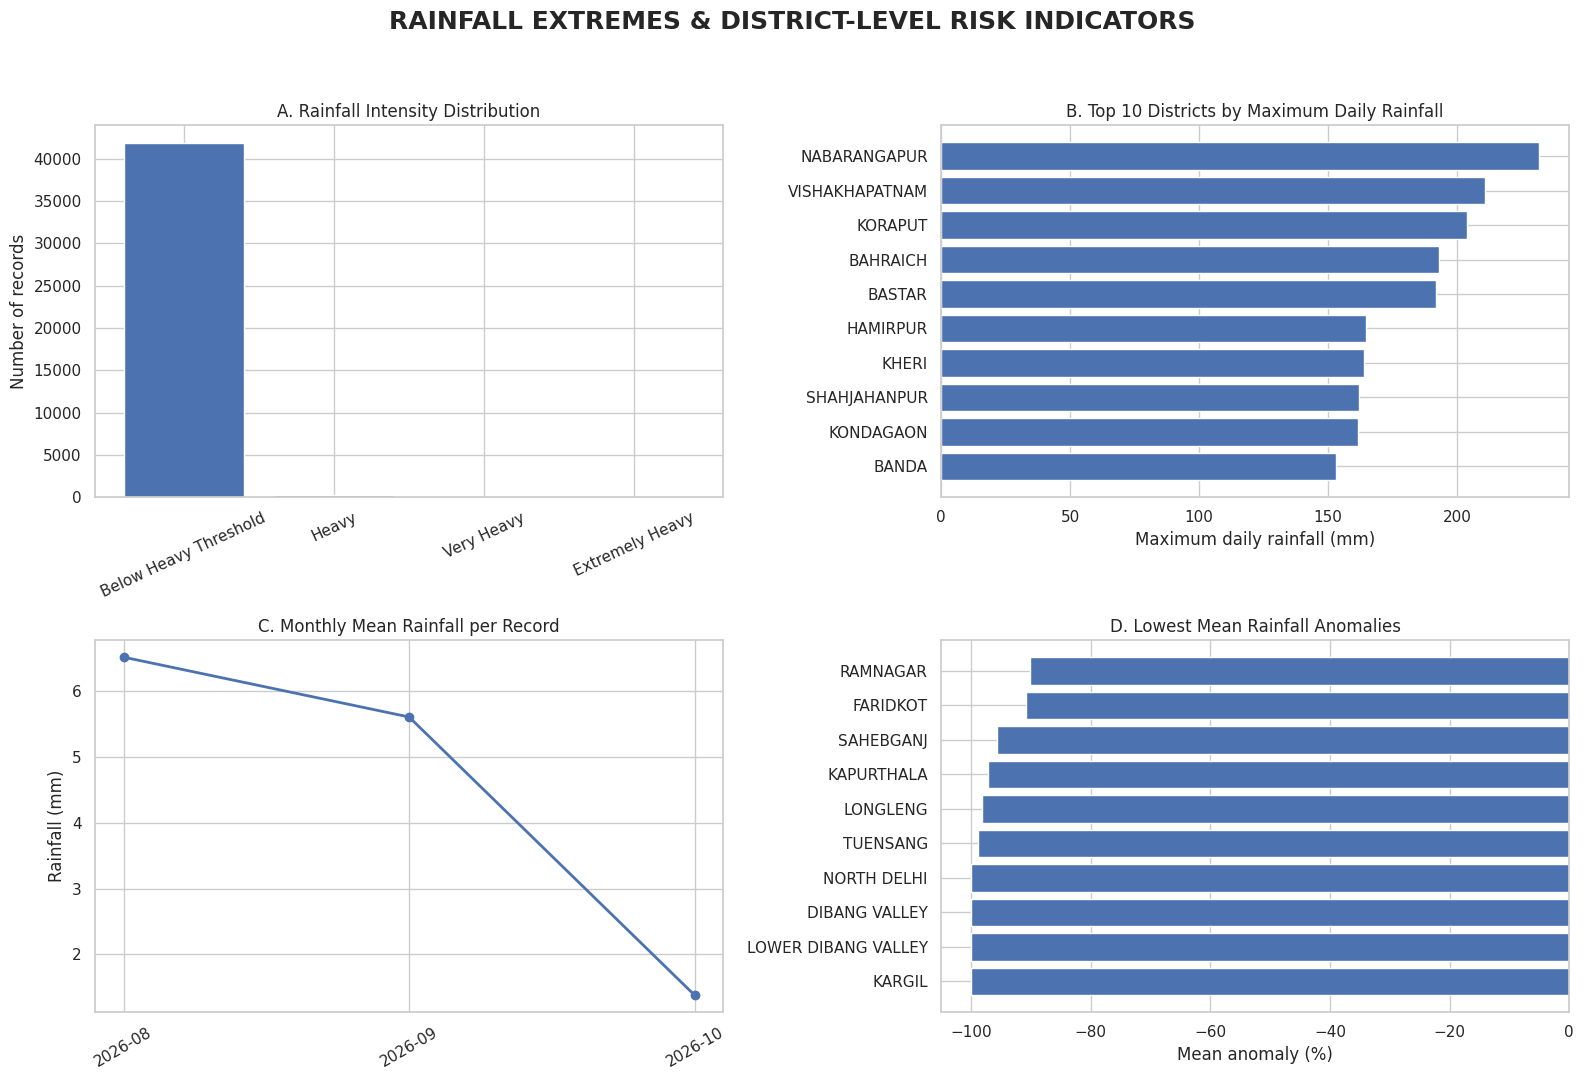

Conference dashboard saved.


In [ ]:

intensity_pd = intensity_summary.toPandas()
district_pd = district_summary.toPandas()
monthly_pd = monthly_summary.toPandas()

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(
    "RAINFALL EXTREMES & DISTRICT-LEVEL RISK INDICATORS",
    fontsize=18,
    fontweight="bold"
)

# Chart 1: rainfall intensity
axes[0, 0].bar(
    intensity_pd["rainfall_category"],
    intensity_pd["records"]
)
axes[0, 0].set_title("A. Rainfall Intensity Distribution")
axes[0, 0].set_ylabel("Number of records")
axes[0, 0].tick_params(axis="x", rotation=25)

# Chart 2: district maxima
top10 = district_pd.nlargest(10, "maximum_daily_mm")
axes[0, 1].barh(
    top10["analysis_district"],
    top10["maximum_daily_mm"]
)
axes[0, 1].invert_yaxis()
axes[0, 1].set_title("B. Top 10 Districts by Maximum Daily Rainfall")
axes[0, 1].set_xlabel("Maximum daily rainfall (mm)")

# Chart 3: monthly mean record rainfall
axes[1, 0].plot(
    monthly_pd["month_name"],
    monthly_pd["mean_record_rainfall_mm"],
    marker="o",
    linewidth=2
)
axes[1, 0].set_title("C. Monthly Mean Rainfall per Record")
axes[1, 0].set_ylabel("Rainfall (mm)")
axes[1, 0].tick_params(axis="x", rotation=30)

# Chart 4: anomaly or dry-spell screening
if anomaly_summary is not None:
    anomaly_pd = anomaly_summary.toPandas()
    anomaly_pd = anomaly_pd.dropna(
        subset=["mean_anomaly_pct"]
    ).sort_values("mean_anomaly_pct").head(10)

    axes[1, 1].barh(
        anomaly_pd["analysis_district"],
        anomaly_pd["mean_anomaly_pct"]
    )
    axes[1, 1].set_title("D. Lowest Mean Rainfall Anomalies")
    axes[1, 1].set_xlabel("Mean anomaly (%)")
else:
    dry_pd = dry_summary.toPandas().nlargest(
        10, "consecutive_dry_day_transitions"
    )
    axes[1, 1].barh(
        dry_pd["analysis_district"],
        dry_pd["consecutive_dry_day_transitions"]
    )
    axes[1, 1].set_title("D. Preliminary Dry-Spell Indicators")
    axes[1, 1].set_xlabel("Consecutive dry-day transitions")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(
    "rainfall_conference_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Conference dashboard saved.")


In [ ]:

OUTPUT_DIR = "rainfall_analysis_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def export_spark_df(spark_df, filename):
    if spark_df is not None:
        spark_df.toPandas().to_csv(
            os.path.join(OUTPUT_DIR, filename),
            index=False
        )

export_spark_df(
    intensity_summary, "rainfall_intensity_summary.csv"
)
export_spark_df(
    district_summary, "district_risk_indicators.csv"
)
export_spark_df(
    monthly_summary, "monthly_rainfall_summary.csv"
)
export_spark_df(
    dry_summary, "dry_spell_screening.csv"
)

if anomaly_summary is not None:
    export_spark_df(
        anomaly_summary, "rainfall_anomaly_summary.csv"
    )

df.toPandas().to_csv(
    os.path.join(OUTPUT_DIR, "cleaned_rainfall_data.csv"),
    index=False
)

# Data-derived project summary
quality = df.agg(
    F.count("*").alias("records"),
    F.countDistinct("analysis_district").alias("districts"),
    F.min("observation_date").alias("start_date"),
    F.max("observation_date").alias("end_date"),
    F.round(F.avg("daily_rainfall_mm"), 2).alias("mean_mm"),
    F.round(F.max("daily_rainfall_mm"), 2).alias("maximum_mm")
).first()

with open(
    os.path.join(OUTPUT_DIR, "project_summary.txt"),
    "w"
) as f:
    f.write("RAINFALL IMPACT ANALYSIS: SUMMARY\n")
    f.write(f"Records analysed: {quality['records']}\n")
    f.write(f"Districts represented: {quality['districts']}\n")
    f.write(f"Start date: {quality['start_date']}\n")
    f.write(f"End date: {quality['end_date']}\n")
    f.write(f"Mean rainfall per record (mm): {quality['mean_mm']}\n")
    f.write(f"Maximum daily rainfall (mm): {quality['maximum_mm']}\n")
    f.write("\nLimitations:\n")
    f.write("Rainfall thresholds are indicators, not confirmed floods.\n")
    f.write("Dry-spell screening is not official drought classification.\n")
    f.write("Short time coverage cannot establish climate-change trends.\n")

with zipfile.ZipFile(
    "rainfall_conference_results.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as z:
    for root, _, filenames in os.walk(OUTPUT_DIR):
        for filename in filenames:
            path = os.path.join(root, filename)
            z.write(path, arcname=os.path.relpath(path, OUTPUT_DIR))

    z.write("rainfall_conference_dashboard.png")

print("Analysis complete.")
print("Records:", quality["records"])
print("Districts:", quality["districts"])
print("Period:", quality["start_date"], "to", quality["end_date"])
print("Maximum daily rainfall:", quality["maximum_mm"], "mm")

files.download("rainfall_conference_results.zip")
files.download("rainfall_conference_dashboard.png")


Analysis complete.
Records: 42190
Districts: 728
Period: 2026-08-19 to 2026-10-15
Maximum daily rainfall: 231.9 mm


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>